# Dynamic yield curves and fixed-income risk
A chronological extension of the accompanying Nelson–Siegel and PCA study. The first year selects curve shapes. The second year tests interpolation and forecasts. The risk case translates the final observed curve into dollar sensitivity for a specified hypothetical portfolio. Run from the extracted folder.

In [1]:
from pathlib import Path
from itertools import permutations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import subspace_angles

out = Path("advanced_results")
out.mkdir(exist_ok=True)
rates = pd.read_csv("data/treasury_yields.csv",index_col="Date",parse_dates=True).sort_index()
assert rates.index.is_unique and not rates.isna().any().any()
maturity = np.array([int(c[:-1]) for c in rates.columns])
Y = rates.to_numpy()
train = rates.index.year == 2023
test = rates.index.year == 2024
assert train.sum() == test.sum() == 250
def design(t, decays):
    t = np.asarray(t)
    x = t*decays[0]
    short = -np.expm1(-x)/x
    cols = [np.ones(len(t)), short, short-np.exp(-x)]
    if len(decays)==2:
        x = t*decays[1]
        cols.append(-np.expm1(-x)/x-np.exp(-x))
    return np.column_stack(cols)

def tune(t, panel, model):
    grid = np.geomspace(.04, 3.5, 45)
    candidates = [(a,) for a in grid] if model=="NS" else [
        (a,b) for a in grid for b in grid if max(a,b)/min(a,b)>1.5]
    best = None
    for ds in candidates:
        X = design(t, ds)
        if np.linalg.cond(X)>1000:
            continue
        residual = panel - (panel @ np.linalg.pinv(X).T) @ X.T
        loss = np.mean(residual**2)
        if best is None or loss<best[0]:
            best = (loss,ds)
    return best[1]

def infer(panel,t,ds):
    return panel @ np.linalg.pinv(design(t,ds)).T
def errors(bp):
    return {"MAE_bp": np.abs(bp).mean(), "RMSE_bp": np.sqrt(np.mean(bp**2))}

## 1. Does Svensson’s extra bend improve interpolation?
Use 2023 quotes to choose constant decays for each family; recover daily coefficients using that day’s available maturities. The full-curve 2024 error still uses contemporaneous quotes in fitting. For a separate test, remove 7Y from both stages, including the 2023 decay search, and predict it on each 2024 date. Straight-line interpolation uses the 5Y and 10Y neighbours. Rates are in percentage points, errors in basis points.

In [2]:
comparison = []
chosen = {}
keep = maturity != 7
for model in ["NS","NSS"]:
    for case,mask in [("All maturities",np.ones(len(maturity),dtype=bool)),("Unseen 7Y",keep)]:
        ds = tune(maturity[mask],Y[train][:,mask],model)
        b = infer(Y[test][:,mask],maturity[mask],ds)
        eval_t = maturity if case=="All maturities" else [7]
        observed = Y[test] if case=="All maturities" else Y[test][:,~keep]
        error = 100*(b @ design(eval_t,ds).T-observed)
        comparison.append(dict(model=model,test=case,decay_1=ds[0],decay_2=ds[-1] if len(ds)>1 else np.nan,**errors(error)))
        if case=="All maturities": chosen[model]=ds
linear = .6*rates["5Y"]+.4*rates["10Y"]
comparison.append(dict(model="Linear",test="Unseen 7Y",**errors(100*(linear[test]-rates.loc[test,"7Y"]).to_numpy())))
comparison = pd.DataFrame(comparison)
comparison.to_csv(out/"curve_validation.csv",index=False)
print(comparison.round(3).to_string(index=False))

 model           test  decay_1  decay_2  MAE_bp  RMSE_bp
    NS All maturities    0.508      NaN   3.268    4.464
    NS      Unseen 7Y    0.458      NaN   1.964    2.521
   NSS All maturities    0.562    0.066   2.279    2.687
   NSS      Unseen 7Y    0.508    0.066   5.802    6.051
Linear      Unseen 7Y      NaN      NaN   1.081    1.279


## 2. Dynamic Nelson–Siegel and a forecast a trader can benchmark
Use a two-step DNS specification: extract daily level, slope and curvature with the NS shape frozen from 2023, then fit a VAR(1) with intercept to those three factors. For every 2024 target and horizon, refit the VAR through the forecast origin only. Iterate the transition 1, 5 or 20 trading days and reconstruct yields. Benchmark against the last observed curve and frozen last fitted factors. Multi-day errors overlap; differences are descriptive. These are forecasts of published par yields, not bond returns.

In [3]:
ns = chosen["NS"]
X = design(maturity,ns)
factors = infer(Y,maturity,ns)
factor_df=pd.DataFrame(factors,index=rates.index,columns=["level","slope","curvature"])
factor_df.to_csv(out/"dns_factors.csv")
detail = []
for horizon in [1,5,20]:
    for target in np.flatnonzero(test):
        origin = target-horizon
        # Require the whole calibration year to be available at the origin.
        if origin < np.flatnonzero(train)[-1]: continue
        predictors = np.column_stack([np.ones(origin),factors[:origin]])
        transition = np.linalg.lstsq(predictors,factors[1:origin+1],rcond=None)[0]
        predicted = factors[origin].copy()
        for step in range(horizon):
            predicted = np.r_[1.,predicted] @ transition
        for name,forecast in [("DNS VAR",X@predicted),("Last observed",Y[origin]),("Last fitted",X@factors[origin])]:
            for col,actual,estimate in zip(rates.columns,Y[target],forecast):
                detail.append((rates.index[origin],rates.index[target],horizon,name,col,actual,estimate,100*(estimate-actual)))
detail=pd.DataFrame(detail,columns=["origin","target","days","model","maturity","actual_pct","forecast_pct","error_bp"])
assert (detail.origin < detail.target).all()
detail.to_csv(out/"forecast_predictions.csv",index=False)
summary=detail.groupby(["days","model"]).error_bp.agg(MAE_bp=lambda x:x.abs().mean(),RMSE_bp=lambda x:np.sqrt((x*x).mean()))
summary.to_csv(out/"forecast_scores.csv")
print(summary.round(2).to_string())

                    MAE_bp  RMSE_bp
days model                         
1    DNS VAR          5.67     7.31
     Last fitted      5.64     7.24
     Last observed    4.37     5.74
5    DNS VAR         11.37    14.41
     Last fitted     10.56    13.51
     Last observed    9.99    12.82
20   DNS VAR         23.41    29.95
     Last fitted     21.45    26.08
     Last observed   21.17    25.75


## 3. Rolling PCA and factor stability
Use 63 consecutive daily yield changes in basis points per window. Fit covariance PCA by singular value decomposition. Match the first three directions to the fixed 2023 reference by maximising summed absolute cosine similarity over all six permutations and aligning signs. Evaluate only windows ending in 2024. A score near 1 means similar weights. The largest principal angle measures rotation of their combined subspace, even when individual PCs swap.

        level_like  tilt_like  third_direction  max_angle_deg
min          0.973      0.940            0.000          6.642
median       0.992      0.978            0.886         26.129
max          0.998      0.998            0.992         89.974


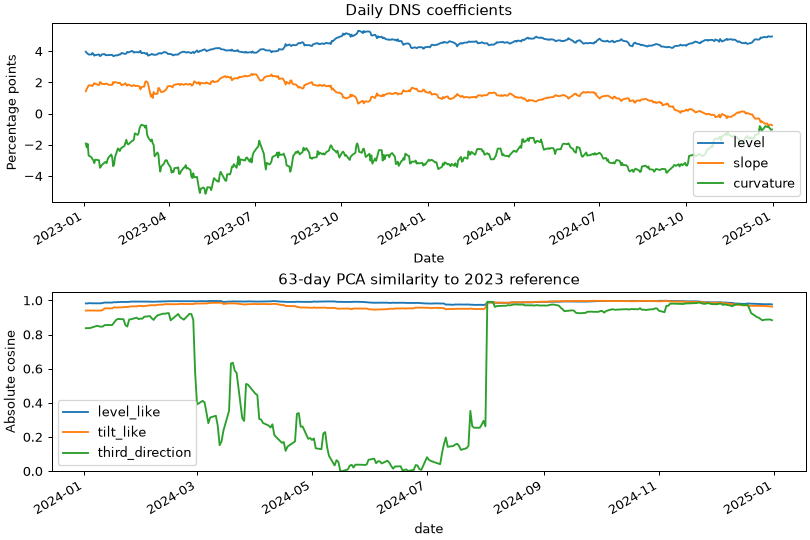

In [4]:
moves=rates.diff().dropna()*100
def pca(v):
    _,s,V=np.linalg.svd(v-v.mean(axis=0),full_matrices=False)
    return V[:3],s[:3]**2/(s**2).sum()
reference,_=pca(moves.loc["2023"].to_numpy())
windows=[]
for i in range(62,len(moves)):
    date=moves.index[i]
    if date.year!=2024: continue
    basis,share=pca(moves.iloc[i-62:i+1].to_numpy())
    cross=reference@basis.T
    order=list(max(permutations(range(3)),key=lambda p:sum(abs(cross[k,p[k]]) for k in range(3))))
    aligned=basis[order].copy()
    dots=(aligned*reference).sum(axis=1)
    aligned*=np.where(dots<0,-1.,1.)[:,None]
    angles=np.degrees(subspace_angles(reference.T,aligned.T))
    windows.append([date,*abs(dots),*share[order],max(angles)])
rolling=pd.DataFrame(windows,columns=["date","level_like","tilt_like","third_direction","share_1","share_2","share_3","max_angle_deg"]).set_index("date")
rolling.to_csv(out/"rolling_pca.csv")
print(rolling[["level_like","tilt_like","third_direction","max_angle_deg"]].agg(["min","median","max"]).round(3))
fig,axes=plt.subplots(2,1,figsize=(9,6),layout="constrained")
factor_df.plot(ax=axes[0],title="Daily DNS coefficients",ylabel="Percentage points")
rolling.iloc[:,:3].plot(ax=axes[1],title="63-day PCA similarity to 2023 reference",ylabel="Absolute cosine",ylim=(0,1.05))
fig.savefig(out/"factor_stability.png",dpi=140)
plt.show()

## 4. From par yields to cash-flow risk
Price a hypothetical USD portfolio as of the final sample date. Each bond pays a fixed annual coupon in two equal instalments. Face value is USD 1 million per bond. Settlement is on a coupon date, with no accrued interest. Linearly interpolate the annual par yields to half-year dates, using 1Y for the missing 6M quote. Recursively solve discount factors so every semiannual par instrument prices to 100. Convert to continuously compounded zero rates. Duration and convexity below describe parallel changes to those zero rates. DV01 is a positive dollar loss magnitude for a 1 bp rise, approximated by the central bump. Stress P&L is signed and obtained by full repricing.

               PV_USD  duration_years  convexity_years2  DV01_USD
2Y          995252.43            1.94              3.84    193.25
5Y         1005346.85            4.53             21.84    455.76
10Y         953620.14            8.28             77.17    789.54
30Y         955551.60           16.32            379.86   1559.29
Portfolio  3909771.02            7.67            118.25   2997.84
                                      2Y       5Y      10Y       30Y  Portfolio  Duration_convexity_estimate
Parallel zero +100 bp           -19136.0 -44496.0 -75390.0 -139267.0  -278289.0                    -276667.0
Parallel zero -100 bp            19517.0  46692.0  82754.0  175786.0   324750.0                     322901.0
Steepener par -25/+25 bp          4419.0   8139.0   7308.0  -38698.0   -18832.0                          NaN
Belly par +50 bp                 -2368.0 -22139.0 -30472.0     844.0   -54136.0                          NaN
Replay Oct 16–20 2023 par moves    379.0  -6236.0 -17081.0 

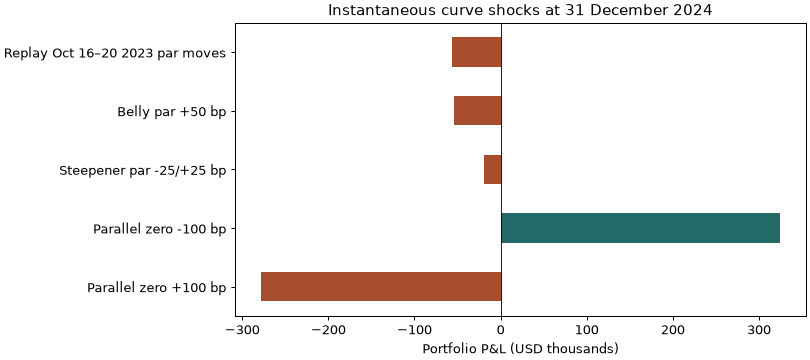

In [5]:
times=np.arange(.5,30.01,.5)
def bootstrap(par):
    coupon=np.interp(times,maturity,par)/200
    discounts=[]
    for c in coupon:
        discounts.append((1-c*sum(discounts))/(1+c))
    d=np.array(discounts)
    assert np.all(d>0) and np.allclose(coupon*np.cumsum(d)+d,1)
    return -np.log(d)/times

zeros=bootstrap(Y[-1])
bond_specs=[(2,.04),(5,.045),(10,.04),(30,.045)]
cash=np.zeros((len(bond_specs),len(times)))
for i,(tenor,coupon) in enumerate(bond_specs):
    cash[i,times<=tenor]=1e6*coupon/2
    cash[i,times==tenor]+=1e6
def pv(curve): return cash@np.exp(-curve*times)
base=pv(zeros)
disc_cash=cash*np.exp(-zeros*times)
duration=(disc_cash@times)/base
convexity=(disc_cash@(times**2))/base
bump=.0001
dv01=(pv(zeros-bump)-pv(zeros+bump))/2
assert np.allclose(dv01,base*duration*bump,rtol=2e-6)
risk=pd.DataFrame({"PV_USD":base,"duration_years":duration,"convexity_years2":convexity,"DV01_USD":dv01},index=[str(t)+"Y" for t,_ in bond_specs])
risk.loc["Portfolio"]=[sum(base),base@duration/sum(base),base@convexity/sum(base),sum(dv01)]
risk.to_csv(out/"bond_risk.csv")
print(risk.round(2).to_string())
history=rates.loc["2023-10-20"]-rates.loc["2023-10-16"]
scenarios={"Parallel zero +100 bp":zeros+.01,"Parallel zero -100 bp":zeros-.01,
           "Steepener par -25/+25 bp":bootstrap(Y[-1]+np.interp(maturity,[1,30],[-.25,.25])),
           "Belly par +50 bp":bootstrap(Y[-1]+np.interp(maturity,[1,5,30],[0,.5,0])),
           "Replay Oct 16–20 2023 par moves":bootstrap(Y[-1]+history.to_numpy())}
stress=pd.DataFrame({name:pv(shocked)-base for name,shocked in scenarios.items()},index=risk.index[:-1]).T
stress["Portfolio"]=stress.sum(axis=1)
stress["Duration_convexity_estimate"]=np.nan
for name,dy in [("Parallel zero +100 bp",.01),("Parallel zero -100 bp",-.01)]:
    stress.loc[name,"Duration_convexity_estimate"]=sum(base*(-duration*dy+.5*convexity*dy**2))
stress.to_csv(out/"stress_pnl_usd.csv")
print(stress.round(0).to_string())
fig,ax=plt.subplots(figsize=(9,4),layout="constrained")
stress.Portfolio.div(1000).plot.barh(ax=ax,color=["#a94d31" if p<0 else "#236a68" for p in stress.Portfolio])
ax.set(xlabel="Portfolio P&L (USD thousands)",ylabel="",title="Instantaneous curve shocks at 31 December 2024")
ax.axvline(0,color="black",lw=.7)
fig.savefig(out/"stress_pnl.png",dpi=140)
plt.show()

## Reading the results
Use the lower 7Y holdout error to assess interpolation; full-curve errors reward flexibility. Compare forecast RMSE with the last observed quote at each horizon. Weak individual PCA stability can coexist with a stable three-dimensional subspace. DV01 covers a small parallel zero-rate move; inspect the repriced scenario table for steepeners and middle-maturity shocks. Full repricing assumes immediate shocks, fixed cash flows, and no carry, credit spread or transaction costs.

[US Treasury benchmark yields](https://home.treasury.gov/resource-center/data-chart-center/interest-rates/TextView?type=daily_treasury_yield_curve) · [Diebold and Li, forecasting the term structure](https://www.nber.org/papers/w10048) · [BIS technical documentation on zero-coupon yield curves](https://www.bis.org/publ/bppdf/bispap25.htm)